## Polynomial & Interaction Terms

### 1. Dependencies

In [1]:
from prep import *
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.base import BaseEstimator, TransformerMixin

X_train, X_test, y_train, y_test, meta = load_model_data()
print(f"{X_train.shape[1]} lagged features, {len(X_train)} training quarters")

train 1992-03-31 to 2014-12-31  (92, 25)
test  2015-03-31 to 2025-12-31  (44, 25)
25 lagged features, 92 training quarters


### 2. Baseline Model

In [2]:
linear = make_pipeline(*preprocess(scale=True), LinearRegression()).fit(X_train, y_train)
score(linear, X_train, X_test, y_train, y_test)

,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.163,0.103,0.925,0.750,92.0
model - test,0.373,0.174,-1.143,0.614,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.130,0.105,0.620,0.583,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


In [3]:
record("Linear (no extra terms)", linear, X_train, X_test, y_train, y_test,
       notes="OLS on lagged features, baseline for notebook 1")

recorded 'Linear (no extra terms)' -> /workspaces/DX799-O1/model_data/results


,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.163,0.103,0.925,0.750,92.0
model - test,0.373,0.174,-1.143,0.614,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.130,0.105,0.620,0.583,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


### > **Note:** Below are all the possible interaction terms available.

In [4]:
p = X_train.shape[1]
rows = []
for degree in [1, 2, 3]:
    for inter_only in [False, True]:
        n = PolynomialFeatures(degree, interaction_only=inter_only, include_bias=False).fit(X_train.fillna(0)).n_output_features_
        rows.append({"degree": degree, "interaction_only": inter_only, "terms": n,
                     "terms per training quarter": round(n / len(X_train), 1)})
pd.DataFrame(rows)

,degree,interaction_only,terms,terms per training quarter
0,1,False,25,0.3
1,1,True,25,0.3
2,2,False,350,3.8
3,2,True,325,3.5
4,3,False,3275,35.6
5,3,True,2625,28.5


> **Add. Note:** Degree 3 is skipped since there is no economic reason for it and it adds unnecessary model complexity.

### 3. All Poly Terms + Ridge (for regularization) | A

In [5]:
poly_pipe = make_pipeline(*preprocess(scale=False),
                          PolynomialFeatures(include_bias=False),
                          StandardScaler(),
                          Ridge())
poly_grid = {"polynomialfeatures__degree": [1, 2],
             "polynomialfeatures__interaction_only": [False, True],
             "ridge__alpha": np.logspace(-2, 5, 30)}
poly_search = tune(poly_pipe, poly_grid, X_train, y_train)
poly_best = poly_search.best_estimator_

best params: {'polynomialfeatures__degree': 1, 'polynomialfeatures__interaction_only': False, 'ridge__alpha': np.float64(23.95026619987486)}
best CV root_mean_squared_error: 0.4005


#### 1. Penalty and Degree Effect

<Axes: title={'center': 'Tuning: alpha by degree'}, xlabel='alpha', ylabel='root mean squared error'>

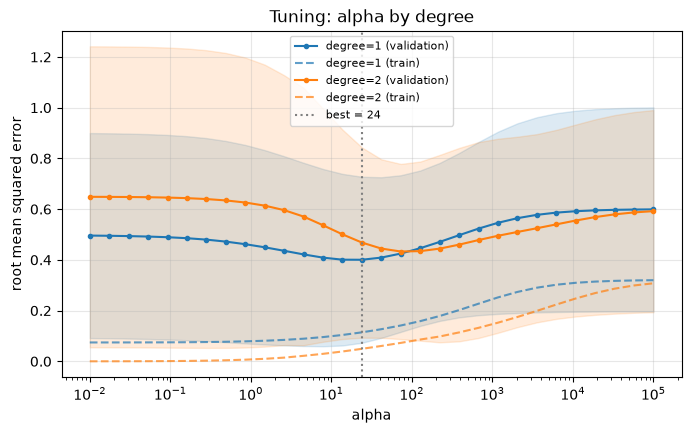

In [6]:
plot_tuning(poly_search, "ridge__alpha", by="polynomialfeatures__degree")

<Axes: title={'center': 'CV root mean squared error'}, xlabel='interaction_only', ylabel='degree'>

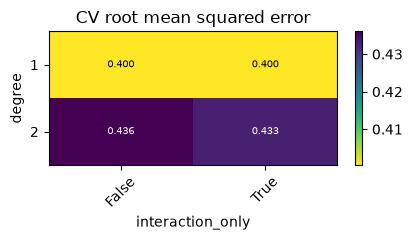

In [7]:
# best CV RMSE for each degree / interaction_only combination (each at its own best alpha)
plot_tuning_heatmap(poly_search, "polynomialfeatures__interaction_only", "polynomialfeatures__degree", fmt=".3f")

In [9]:
tuning_table(poly_search, top=20)

,polynomialfeatures__degree,polynomialfeatures__interaction_only,ridge__alpha,cv_root_mean_squared_error,cv_root_mean_squared_error_sd,train_root_mean_squared_error,gap (cv - train),rank
0,1,False,23.950266,0.400470,0.327247,0.114285,0.286185,1
1,1,True,23.950266,0.400470,0.327247,0.114285,0.286185,1
2,1,True,13.738238,0.400759,0.338317,0.103912,0.296847,3
3,1,False,13.738238,0.400759,0.338317,0.103912,0.296847,3
4,1,False,7.880463,0.408852,0.349516,0.095586,0.313266,5
5,1,True,7.880463,0.408852,0.349516,0.095586,0.313266,5
6,1,True,41.753189,0.409021,0.316684,0.126695,0.282327,7
7,1,False,41.753189,0.409021,0.316684,0.126695,0.282327,7
8,1,False,4.520354,0.421539,0.361206,0.089223,0.332316,9
9,1,True,4.520354,0.421539,0.361206,0.089223,0.332316,9


#### 2. Accuracy

In [10]:
score(poly_best, X_train, X_test, y_train, y_test)

,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.198,0.141,0.889,0.630,92.0
model - test,0.390,0.212,-1.348,0.614,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.169,0.147,0.355,0.667,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


<Axes: title={'center': 'Polynomial + Ridge: actual vs forecast'}, ylabel='co_other_cons'>

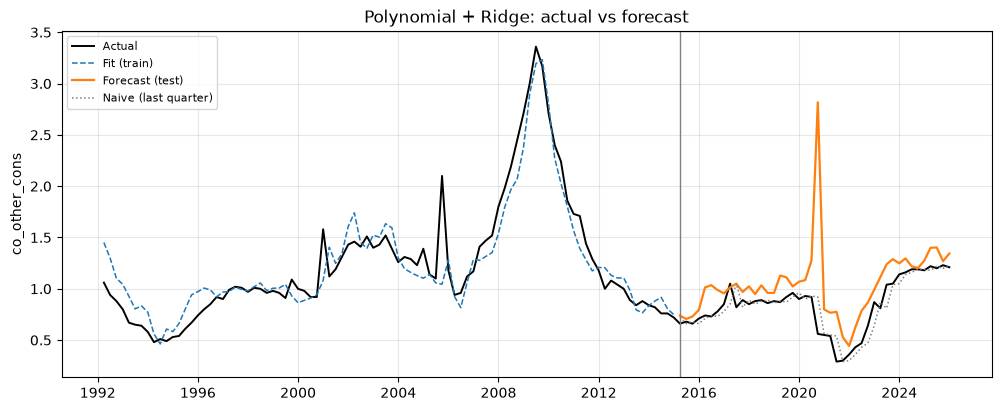

In [11]:
plot_forecast(poly_best, X_train, X_test, y_train, y_test, title="Polynomial + Ridge: actual vs forecast")

#### 3. Important Terms in the Model

In [12]:
w = feature_weights(poly_best, X_train)
print(f"{len(w)} terms; showing the largest")
w.head(20)

25 terms; showing the largest


,feature,weight,abs weight,used,variable
0,co_other_cons_L1,0.219771,0.219771,True,co_other_cons
1,emp_constr_L1,-0.070492,0.070492,True,emp_constr
2,emp_constr_L2,-0.061527,0.061527,True,emp_constr
3,dq_other_cons_L2,0.053003,0.053003,True,dq_other_cons
4,dq_other_cons_L1,0.050472,0.050472,True,dq_other_cons
5,emp_info_L1,-0.044062,0.044062,True,emp_info
6,credit_cons_total_L1,-0.033533,0.033533,True,credit_cons_total
7,stk_vix_L2,0.031212,0.031212,True,stk_vix
8,house_cs10_L1,-0.023820,0.023820,True,house_cs10
9,sent_consumer_L4,0.022388,0.022388,True,sent_consumer


<Axes: title={'center': 'Feature weights (coefficient)'}>

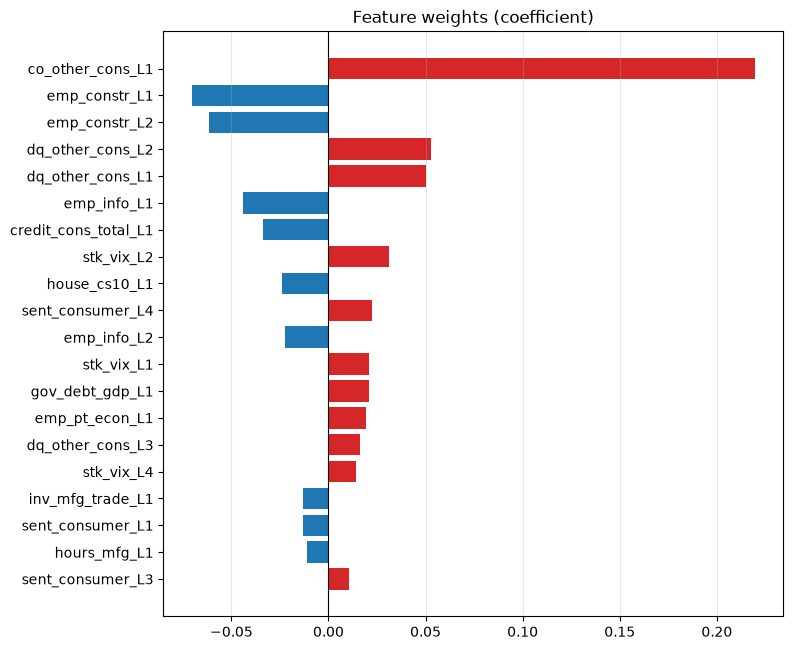

In [13]:
plot_feature_weights(poly_best, X_train, top=20)

In [14]:
# how much weight went to original features vs squares vs interactions
w["term type"] = np.where(w["feature"].str.contains(r"\^2"), "squared",
                  np.where(w["feature"].str.contains(" "), "interaction", "original (linear)"))
w.groupby("term type")["abs weight"].agg(["count", "sum"]).assign(share=lambda d: d["sum"] / d["sum"].sum()).round(3)

,count,sum,share
term type,,,
original (linear),25,0.801,1.0


#### 4. Overfitting

<Axes: title={'center': 'Permutation importance (big train, small test = likely overfit)'}, xlabel='drop in root_mean_squared_error when shuffled'>

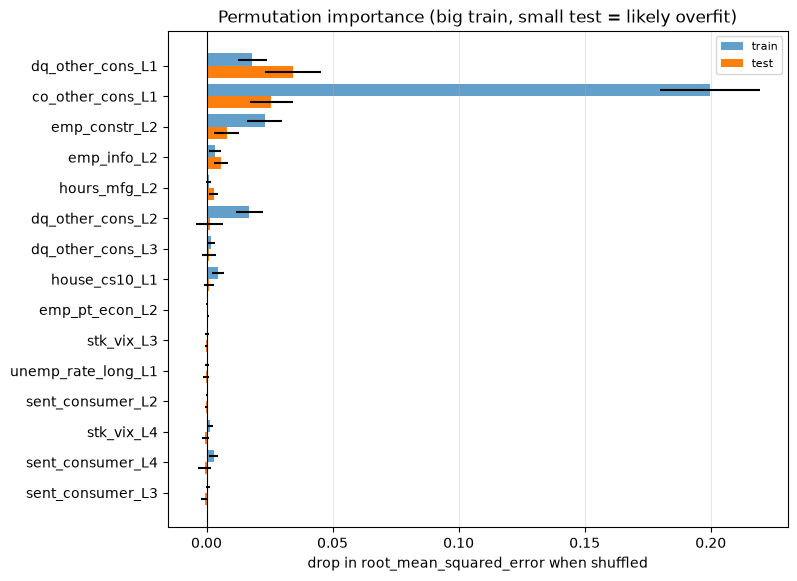

In [15]:
perm_poly = permutation_table(poly_best, X_train, y_train, X_test, y_test, n_repeats=20)
plot_permutation(perm_poly, top=15)

In [16]:
record("Poly + Ridge", poly_best, X_train, X_test, y_train, y_test, search=poly_search,
       notes="PolynomialFeatures -> StandardScaler -> Ridge")

recorded 'Poly + Ridge' -> /workspaces/DX799-O1/model_data/results


,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.198,0.141,0.889,0.630,92.0
model - test,0.390,0.212,-1.348,0.614,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.169,0.147,0.355,0.667,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


### 4. Few Targeted/Selected Terms | B

In [17]:
class AddTerms(BaseEstimator, TransformerMixin):
    # Adds chosen interaction (a x b) and squared (a^2) columns. Pure arithmetic on each row,
    # nothing is learned from the data, so it cannot leak information between train and test.
    def __init__(self, pairs=(), squares=()):
        self.pairs, self.squares = pairs, squares
    def fit(self, X, y=None):
        self.feature_names_in_ = np.array(X.columns)
        return self
    def transform(self, X):
        X = X.copy()
        for a, b in self.pairs:
            X[f"{a} x {b}"] = X[a] * X[b]
        for a in self.squares:
            X[f"{a}^2"] = X[a] ** 2
        return X
    def get_feature_names_out(self, input_features=None):
        return np.array(list(self.feature_names_in_)
                        + [f"{a} x {b}" for a, b in self.pairs] + [f"{a}^2" for a in self.squares])

> **Note:** Here below I hand pick which pairs and squares go into the model

In [18]:
# candidate terms with an economic story; anything not in X_train is skipped
PAIRS = [
    ("dq_other_cons_L1", "unemp_rate_L1"),     # delinquencies roll into charge-offs faster when jobs are scarce
    ("dq_other_cons_L1", "house_price_idx_L1"),# less home equity -> fewer ways to cure a late loan
    ("co_credit_card_L1", "unemp_rate_L1"),    # card stress spreading to installment loans in weak labor markets
    ("spr_baa_10y_L1", "unemp_rate_L1"),       # credit stress and job losses together
]
SQUARES = ["unemp_rate_L1", "spr_baa_10y_L1"]  # effects that may grow faster at extremes

have = set(X_train.columns)
PAIRS = [(a, b) for a, b in PAIRS if a in have and b in have]
SQUARES = [a for a in SQUARES if a in have]
print("pairs used:", PAIRS)
print("squares used:", SQUARES)

pairs used: []
squares used: []


> **Note:** Tuning - All combinations of terms are tested: No extra terms vs squares vs interactions vs both together. Along with CV to determine which work best.

In [19]:
term_options = {
    "none": dict(pairs=(), squares=()),
    "squares": dict(pairs=(), squares=tuple(SQUARES)),
    "interactions": dict(pairs=tuple(PAIRS), squares=()),
    "both": dict(pairs=tuple(PAIRS), squares=tuple(SQUARES)),
}
target_pipe = make_pipeline(AddTerms(), *preprocess(scale=True), Ridge())
target_grid = [{"addterms__pairs": [o["pairs"]], "addterms__squares": [o["squares"]],
                "ridge__alpha": np.logspace(-3, 4, 25)} for o in term_options.values()]
target_search = tune(target_pipe, target_grid, X_train, y_train)
target_best = target_search.best_estimator_

best params: {'addterms__pairs': (), 'addterms__squares': (), 'ridge__alpha': np.float64(23.71373705661655)}
best CV root_mean_squared_error: 0.4004


In [20]:
# best CV score for each option (each at its own best alpha)
t = tuning_table(target_search)
label = {(str(o["pairs"]), str(o["squares"])): k for k, o in term_options.items()}
t["terms added"] = [label[(str(p), str(s))] for p, s in zip(t["addterms__pairs"], t["addterms__squares"])]
t.sort_values("rank").groupby("terms added", sort=False).first()[["ridge__alpha", "cv_root_mean_squared_error", "train_root_mean_squared_error"]]

,ridge__alpha,cv_root_mean_squared_error,train_root_mean_squared_error
terms added,,,
both,23.713737,0.400396,0.114082


#### 1. Accuracy

In [21]:
score(target_best, X_train, X_test, y_train, y_test)

,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.197,0.140,0.890,0.630,92.0
model - test,0.389,0.211,-1.341,0.591,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.169,0.146,0.358,0.639,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


#### 2. Weights

<Axes: title={'center': 'Targeted terms + Ridge: weights'}>

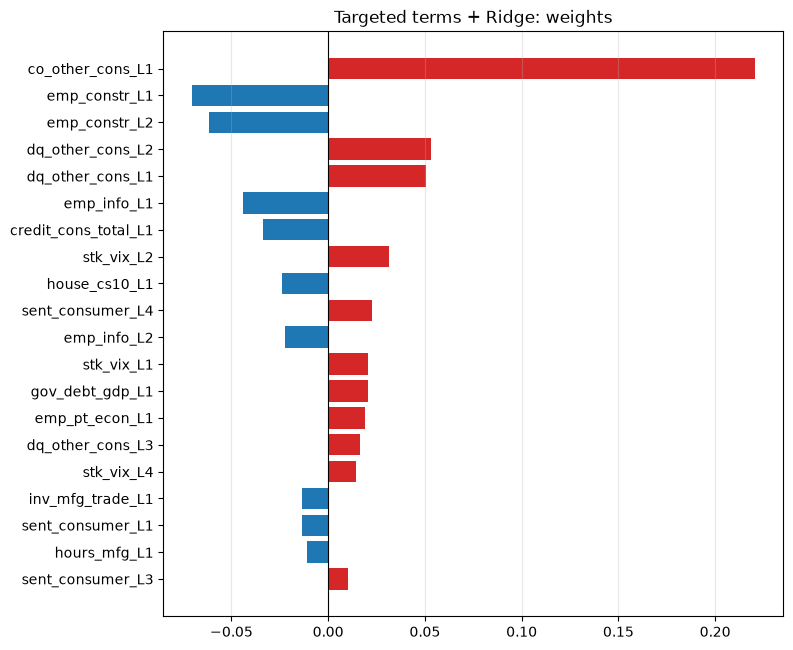

In [22]:
plot_feature_weights(target_best, X_train, top=20, title="Targeted terms + Ridge: weights")

,full-training weight,mean across folds,sd across folds,share of folds used,sign flips
feature,,,,,


<Axes: title={'center': 'Weight stability across time folds (dots = folds, bar = full training)'}>

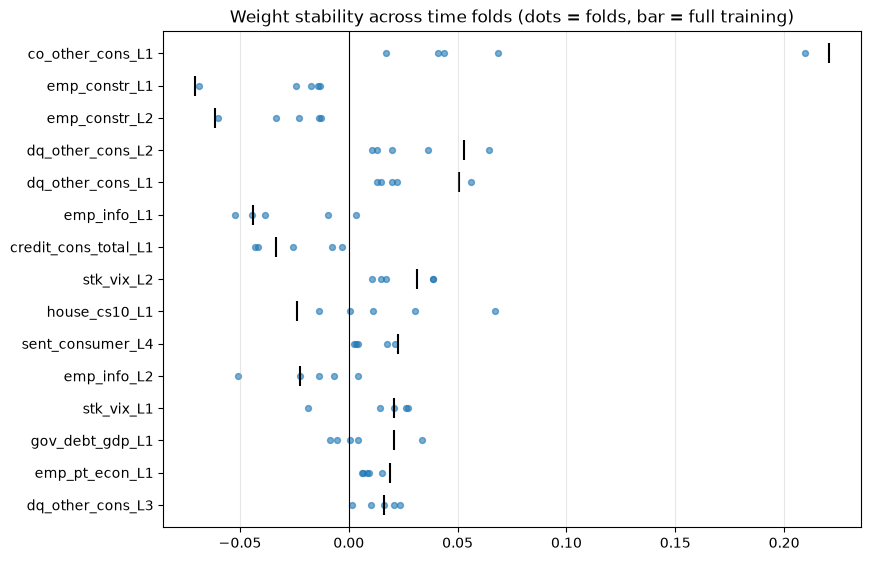

In [23]:
W_t, stab_t = weight_stability(target_best, X_train, y_train)
display(stab_t[stab_t.index.str.contains(r" x |\^2", regex=True)])   # are the added terms stable across folds?
plot_weight_stability(W_t, top=15)

In [24]:
record("Targeted terms + Ridge", target_best, X_train, X_test, y_train, y_test, search=target_search,
       notes=f"pairs={PAIRS}; squares={SQUARES}")

recorded 'Targeted terms + Ridge' -> /workspaces/DX799-O1/model_data/results


,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.197,0.140,0.890,0.630,92.0
model - test,0.389,0.211,-1.341,0.591,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.169,0.146,0.358,0.639,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


### 5. Comparing A and B Models

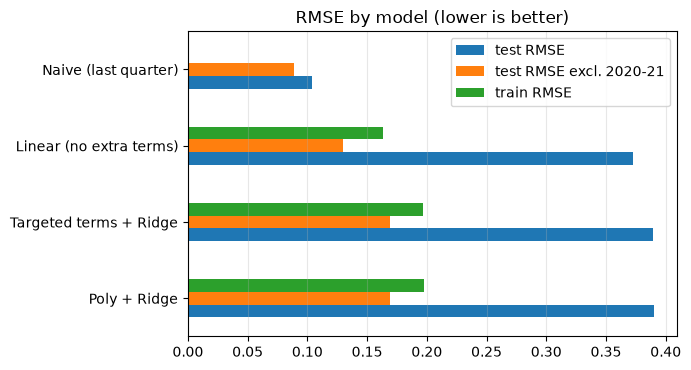

,type,test RMSE,test MAE,test R2,test DirAcc,test RMSE excl. 2020-21,train RMSE,overfit gap (test - train RMSE),CV score,CV metric,best params,saved
Naive (last quarter),baseline,0.104,0.066,0.832,NaN,0.089,NaN,NaN,NaN,NaN,NaN,NaN
Linear (no extra terms),regressor,0.373,0.174,-1.143,0.614,0.13,0.163,0.21,None,None,None,2026-10-18 00:11
Targeted terms + Ridge,regressor,0.389,0.211,-1.341,0.591,0.169,0.197,0.192,0.400396,root_mean_squared_error,"{'addterms__pairs': (), 'addterms__squares': (...",2026-10-18 00:36
Poly + Ridge,regressor,0.39,0.212,-1.348,0.614,0.169,0.198,0.192,0.40047,root_mean_squared_error,"{'polynomialfeatures__degree': 1, 'polynomialf...",2026-10-18 00:28


In [25]:
nb1 = ["Linear (no extra terms)", "Poly + Ridge", "Targeted terms + Ridge"]
compare(results={k: v for k, v in load_results().items() if k in nb1})

<Axes: title={'center': 'Test-period forecasts by model'}, ylabel='co_other_cons'>

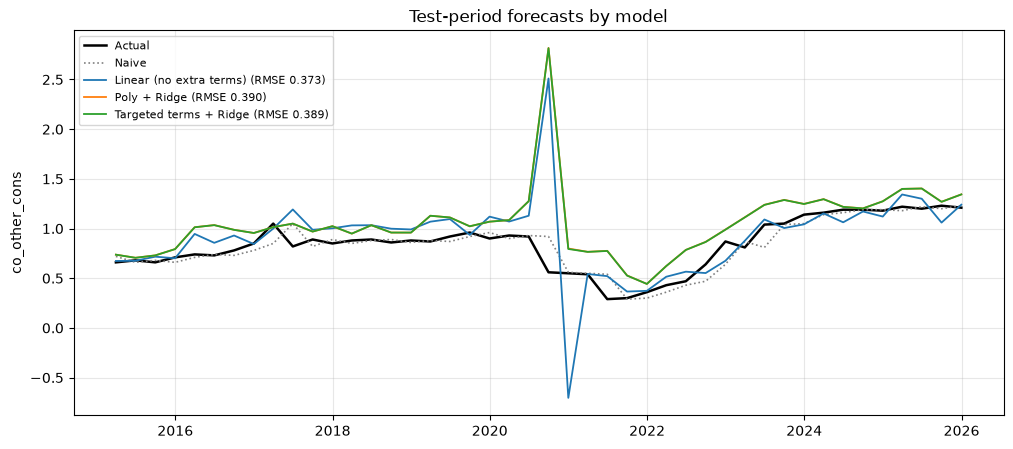

In [26]:
plot_forecasts(names=nb1)

### 6. Notes

- **Did extra terms help?** Compare test RMSE and DirAcc of the two approaches against the linear baseline and the naive forecast.
- **Which terms mattered?** Use the weight charts and the term-type table (share of weight on squares / interactions).
- **Overfitting:** train vs test RMSE gap; permutation importance on train vs test; stability of the added terms across folds.
- **Expected vs unexpected:** e.g. if `dq_other_cons_L1 × unemp_rate_L1` is positive and stable, that matches the idea that late loans roll into losses faster in weak labor markets.